# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [3]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion_model"])
print("Test:", X_test.shape)

Modelo: LogisticRegression
Test: (36, 13)


## 2. Evaluación final

Accuracy test : 0.9722
F1 macro test : 0.9710

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



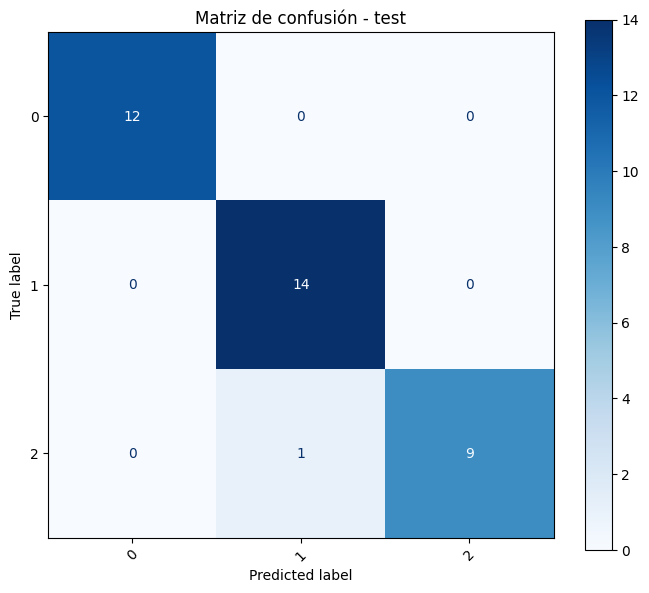

In [4]:
# Predicciones sobre test (única apertura del conjunto de prueba)
y_pred = model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy test : {test_accuracy:.4f}")
print(f"F1 macro test : {test_f1_macro:.4f}\n")
print(classification_report(y_test, y_pred, zero_division=0))

labels = getattr(model, "classes_", np.unique(y_test))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=labels, ax=ax, cmap="Blues", xticks_rotation=45
)
ax.set_title("Matriz de confusión - test")
plt.tight_layout()
plt.show()

In [5]:
from sklearn.metrics import confusion_matrix
from IPython.display import Markdown, display

# --- Métricas de CV guardadas en el challenge 2 (training_metadata.json) ---
cv_accuracy = float(training_metadata["cv_accuracy_mean"])
cv_std = float(training_metadata["cv_accuracy_std"])
cv_train_accuracy = float(training_metadata["cv_train_accuracy_mean"])
print(f"CV (5 folds): accuracy = {cv_accuracy:.4f} +/- {cv_std:.4f} | train en CV = {cv_train_accuracy:.4f}")

# --- Análisis de confusiones ---
cm = confusion_matrix(y_test, y_pred, labels=labels)
off = [(labels[i], labels[j], int(cm[i, j])) for i in range(len(labels))
       for j in range(len(labels)) if i != j and cm[i, j] > 0]
off.sort(key=lambda t: -t[2])
top_conf = off[:3]

report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
per_class_f1 = {str(c): report[str(c)]["f1-score"] for c in labels}
worst_class = min(per_class_f1, key=per_class_f1.get)

GAP_THRESHOLD = 0.05  # SUPUESTO: diferencia CV-test > 5 pts = señal de sobreajuste
gap = cv_accuracy - test_accuracy

lines = ["### Análisis automático", ""]
if gap is None:
    lines.append("**¿Coherente con CV?** No se pudo comparar: falta la accuracy CV en los metadatos.")
else:
    coherent = abs(gap) <= GAP_THRESHOLD
    lines.append(f"**¿Coherente con CV?** {'Sí' if coherent else 'No'}: accuracy CV = {cv_accuracy:.3f} vs "
                 f"test = {test_accuracy:.3f} (diferencia = {gap:+.3f}; umbral = {GAP_THRESHOLD}).")
if top_conf:
    conf_txt = "; ".join(f"{a} -> {b} ({n} casos)" for a, b, n in top_conf)
    lines.append(f"**Clases confundidas:** {conf_txt}.")
else:
    lines.append("**Clases confundidas:** no hay errores en test.")
lines.append(f"**Clase más débil (F1):** {worst_class} ({per_class_f1[worst_class]:.3f}).")
if gap is None:
    lines.append("**¿Sobreajuste?** No evaluable sin la métrica CV.")
elif gap > GAP_THRESHOLD:
    lines.append("**¿Sobreajuste?** Hay indicios: test queda claramente por debajo de CV.")
else:
    lines.append("**¿Sobreajuste?** No hay evidencia: test es similar (o mejor) que CV. "
                 "Nota: con test pequeño la estimación tiene incertidumbre.")
lines.append(f"(n test = {len(y_test)})")
display(Markdown("\n\n".join(lines)))

CV (5 folds): accuracy = 0.9791 +/- 0.0277 | train en CV = 1.0000


### Análisis automático



**¿Coherente con CV?** Sí: accuracy CV = 0.979 vs test = 0.972 (diferencia = +0.007; umbral = 0.05).

**Clases confundidas:** 2 -> 1 (1 casos).

**Clase más débil (F1):** 2 (0.947).

**¿Sobreajuste?** No hay evidencia: test es similar (o mejor) que CV. Nota: con test pequeño la estimación tiene incertidumbre.

(n test = 36)

**Análisis:**

> ¿El desempeño es coherente con validación cruzada? ¿Qué clases se confunden? ¿Hay evidencia de sobreajuste?

**¿Coherente con validación cruzada?** Sí. La regresión logística obtuvo 0.979 de accuracy en CV (± 0.028) y 0.972 en test (35 de 36 aciertos), con F1 macro de 0.971. La diferencia es de 0.7 puntos, mucho menor que la desviación entre folds, y equivale a una sola observación. Por tanto, la estimación del challenge 2 era fiable y no hubo fuga de información hacia test.

**¿Qué clases se confunden?** Hubo un único error: un vino de la clase 2 fue clasificado como clase 1. Eso explica que la clase 2 tenga recall de 0.90 (9/10) y que la clase 1 tenga precision de 0.93 (13/14). La clase 0 se clasificó perfectamente (12/12). Es coherente con que las clases 1 y 2 sean las más próximas entre sí en el espacio de variables.

**¿Hay evidencia de sobreajuste?** No. Aunque el modelo llegaba a 1.00 de accuracy en train durante la CV, en datos nunca vistos mantiene 0.97, es decir, la brecha train–validación (~0.02) se tradujo en una caída pequeña y similar a la esperada. Salvedad: con solo 36 filas de test, un error cambia la accuracy en ~2.8 puntos, así que la estimación tiene bastante incertidumbre y no permite afirmar que sea mejor que KNN (que estaba prácticamente empatado en CV).

## 3. Función de inferencia

In [6]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    if not isinstance(records, pd.DataFrame):
        raise TypeError("records debe ser un pandas.DataFrame")
    if records.empty:
        raise ValueError("records no contiene filas")

    # Columnas faltantes -> error explícito (nunca se rellenan en silencio)
    missing = [c for c in feature_columns if c not in records.columns]
    if missing:
        raise ValueError(f"Faltan columnas requeridas: {missing}")

    # Columnas extra -> se ignoran, pero se avisa
    extra = [c for c in records.columns if c not in feature_columns]
    if extra:
        print(f"AVISO: se ignoran columnas no incluidas en el contrato: {extra}")

    # Mismo orden que en entrenamiento
    X = records[feature_columns].copy()

    out = pd.DataFrame(index=records.index)
    out["prediction"] = model.predict(X)

    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(X)
        for i, cls in enumerate(model.classes_):
            out[f"proba_{cls}"] = proba[:, i]
    else:
        print("AVISO: el modelo no expone predict_proba; se devuelve solo prediction.")
    return out

## 4. Predicción por lotes

In [7]:
# Simulación de datos nuevos. En producción no provendrían del test set.
new_records = X_test.iloc[:5].copy()

batch_predictions = predict(new_records)
print(batch_predictions)

# Comprobación de la validación del esquema: debe fallar con una columna faltante
try:
    predict(new_records.drop(columns=[feature_columns[0]]))
except ValueError as e:
    print("Validación OK ->", e)

batch_predictions.to_csv(REPORTS_DIR / "batch_predictions.csv", index=True, index_label="row_id")
print("Guardado:", REPORTS_DIR / "batch_predictions.csv")

   prediction   proba_0   proba_1   proba_2
0           0  0.999671  0.000307  0.000023
1           1  0.007051  0.540423  0.452526
2           0  0.992000  0.007664  0.000336
3           1  0.289967  0.707467  0.002565
4           1  0.033032  0.962313  0.004655
Validación OK -> Faltan columnas requeridas: ['alcohol']
Guardado: /home/claude/proj/reports/batch_predictions.csv


## 5. Reporte final

In [8]:
test_metrics = {
    "model": training_metadata["champion_model"],
    "accuracy": float(test_accuracy),
    "f1_macro": float(test_f1_macro),
    "n_test": int(len(y_test)),
}
(REPORTS_DIR / "test_metrics.json").write_text(
    json.dumps(test_metrics, indent=2, ensure_ascii=False), encoding="utf-8"
)
print(json.dumps(test_metrics, indent=2, ensure_ascii=False))

{
  "model": "LogisticRegression",
  "accuracy": 0.9722222222222222,
  "f1_macro": 0.9709618874773139,
  "n_test": 36
}


In [9]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


In [10]:
conf_cell = ", ".join(f"{a} -> {b}" for a, b, _ in top_conf) if top_conf else "Sin errores"
cv_cell = f"{cv_accuracy:.3f} (± {cv_std:.3f})"
limit_parts = [f"clase más débil: {worst_class} (F1 = {per_class_f1[worst_class]:.2f})",
               f"test de solo {len(y_test)} filas"]
if gap is not None and gap > GAP_THRESHOLD:
    limit_parts.append("posible sobreajuste")

display(Markdown(f"""
## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | {training_metadata["champion_model"]} |
| Accuracy CV | {cv_cell} |
| Accuracy test | {test_accuracy:.3f} |
| F1 macro test | {test_f1_macro:.3f} |
| Clases más confundidas | {conf_cell} |
| Principal limitación | {"; ".join(limit_parts)} |
"""))


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | LogisticRegression |
| Accuracy CV | 0.979 (± 0.028) |
| Accuracy test | 0.972 |
| F1 macro test | 0.971 |
| Clases más confundidas | 2 -> 1 |
| Principal limitación | clase más débil: 2 (F1 = 0.95); test de solo 36 filas |


## Checklist

- [x] Evalué únicamente el modelo campeón.
- [x] No reajusté hiperparámetros después de observar test.
- [x] Implementé validación básica del esquema de entrada.
- [x] Generé predicciones por lotes.
- [x] Guardé las métricas finales.